# Particle Filtering

### Import the required packages
You are to implement the algorithms yourself and forbided from the use of dedicated packages!

In [ ]:
import numpy as np
import random
import math
from matplotlib import pyplot as plt
from mpl_toolkits.mplot3d import axes3d, Axes3D
from scipy.stats import norm

### Load input data
`input.txt` contains a sample log of vahid's location and `ground_truth.txt` holds the initial state and the hidden state's correrct location at each time-frame, employ it to validate your findings.

In [ ]:
with open("input.txt", "r") as file:
    n, k, mean_pace, t = file.readline().split(" ")
    n, t, k, mean_pace = int(n), int(t), float(k), float(mean_pace)
    sen_error_mean, sen_error_std, sen_xs, sen_ys = list(), list(), list(), list()
    for i in range(n):
        x, y, mu, sig = map(float, file.readline().split(" "))
        sen_xs.append(x)
        sen_ys.append(y)
        sen_error_mean.append(mu)
        sen_error_std.append(sig)
    sen_error_mean = np.array(sen_error_mean)
    sen_error_std = np.array(sen_error_std)
    sens = np.stack([np.array(sen_xs), np.array(sen_ys)], axis=1)
    gt_distances = [
        np.array(list(map(float, file.readline().split(" ")))) for i in range(t)
    ]
with open("ground_truth.txt", "r") as file:
    ground_truth = [
        np.array(list(map(float, line.split(" ")))) for line in file.readlines()
    ]

### Implement utility functions
Implement the utility functions required for particle filtering (the following strucutre is merely a suggestion and you can choose to discard it).

In [3]:
def move(particles: np.array, mean_pace_t: float):
    "sample the next time-frame coordinates"
    # for you to implement

    for particle in particles:
        # randomly select a direction for move and update the particles
        theta = random.uniform(0, 2 * math.pi)

        distance = np.random.exponential(scale=max(mean_pace_t, 1e-12))

        particle[0] += distance * math.cos(theta)
        particle[1] += distance * math.sin(theta)

    # update the mean_pace_t
    mean_pace_t *= k

    return particles, mean_pace_t

In [4]:
def get_distances(particles: np.array, sensors: np.array):
    "utility function to calculate particle distances from sensors"
    # for you to implement

    evidence_distances = []
    # for each particle you need to find its distance to all 7 sensors, for example if you have 1000 particles,
    # the shape of evidence_distances would be (1000, 7).
    # Each particle and each sensor has a location which is a 2-dimensional array. You need to find the euclidean
    # distance between them

    for particle in particles:
        distance = []

        for sensor in sensors:
            d = np.sqrt(np.sum((particle - sensor) ** 2))
            distance.append(d)

        evidence_distances.append(np.array(distance))

    evidence_distances = np.array(evidence_distances)
    return evidence_distances

In [5]:
def get_weights(
    evidence_distances: np.array,
    gt_distances: np.array,
    sen_error_mean: np.array,
    sen_error_std: np.array,
):
    "utility function to calculate distance likelihoods"
    # for you to implement

    likelihoods = []

    for i in range(evidence_distances.shape[0]):
        # for each particle, you calculated 7 distance. You need to find their likelihoods
        # You must use the a suitable probability density function for calculating the likelihood of distances. Notice
        # that the distances has noises. Read that part of the assignment carefully.
        # The likelihoods of distances whose differances to the ground truth distances is smaller must have larger
        # likelihoods.

        likelihood = norm.pdf(
            gt_distances,
            loc=evidence_distances[i] + sen_error_mean,
            scale=np.maximum(sen_error_std, 1e-9),
        )

        likelihoods.append(likelihood)

    likelihoods = np.array(likelihoods)

    # Now you have 7 likelihoods for each particle. Use them to calculate one weight for each particle.
    # Sum of weights must be 1

    likelihoods = np.maximum(likelihoods, 1e-300)
    log_likelihoods = np.sum(np.log(likelihoods), axis=1)
    log_likelihoods -= np.max(log_likelihoods)
    weights = np.exp(log_likelihoods)
    weights /= np.sum(weights)

    return weights

In [6]:
def resample(weights: np.array, particles: np.array):
    "utility function to resample particles"
    # for you to implement

    # You need to selet among the particles. If you have 1000 particles, you must select 1000 particles among them.
    # But this selection is based on the weight of the particles, if weight of a particles. This is called resampling.
    # Save and return the selected particles in "resampled" array.

    indices = np.random.choice(
        len(particles), size=len(particles), replace=True, p=weights
    )

    resampled = particles[indices].copy()

    return resampled

## A. Particle Filtering

In [7]:
# for you to implement
number_of_particles = 1000
std_log = []
particles_log = []
mean_pace_t = mean_pace


particles = np.random.uniform(-100, 100, (number_of_particles, 2))

error_log = [np.mean(np.abs(ground_truth[0] - particles))]
position_log = [np.mean(particles, axis=0)]

for i in range(t):
    if i % 10 == 0:
        print(i)
    # execute the particle filtering process with use of the functions you have completed.

    particles, mean_pace_t = move(particles, mean_pace_t)

    particles = np.clip(particles, -100, 100)

    evidence_distances = get_distances(particles, sens)

    weights = get_weights(
        evidence_distances, gt_distances[i], sen_error_mean, sen_error_std
    )

    estimate = np.sum(particles * weights[:, np.newaxis], axis=0)

    std = np.sqrt(np.sum(weights[:, np.newaxis] * (particles - estimate) ** 2, axis=0))

    particles = resample(weights, particles)

    # save logs
    particles_log.append(particles.copy())
    error_log.append(
        np.mean(np.abs(ground_truth[min(i + 1, len(ground_truth) - 1)] - estimate))
    )
    std_log.append(std)
    position_log.append(estimate)

print("ground truth", *ground_truth[-1])
print("estimated position", *position_log[-1])

0
10
20
30
40
50
ground truth 131.62252381461028 123.0757221368539
estimated position 99.99926428912876 99.99668351898077


In [9]:
print('ground truth', *ground_truth[-1])

ground truth 131.62252381461028 123.0757221368539


Elaborate on why your findings vary from the ground truth? (if they do)

The estimated position may differ from the ground truth for several reasons.

First, particle filtering is a stochastic method. Particles move in randomly sampled directions and travel distances drawn from an exponential distribution, so a finite number of particles cannot represent every possible trajectory.

Second, the cell towers provide noisy distance measurements. Even when the Gaussian noise model is correct, measurement uncertainty can make several different positions similarly likely. The geometry of the tower locations also affects how accurately the position can be determined.

Third, resampling introduces additional sampling variability and may eliminate particles that would have been useful in later time steps. This is known as particle impoverishment.

Finally, the movement model is only an approximation of the individual's actual movement. The estimated pace may differ from the true pace, and the random-motion assumption may not perfectly describe the individual's behavior.

Increasing the number of particles, choosing an appropriate movement parameter, and improving the initialization can potentially reduce the estimation error. However, particle filtering cannot eliminate uncertainty caused by noisy observations or an inaccurate model.

## B. Plot your trajectory prediction and other plots

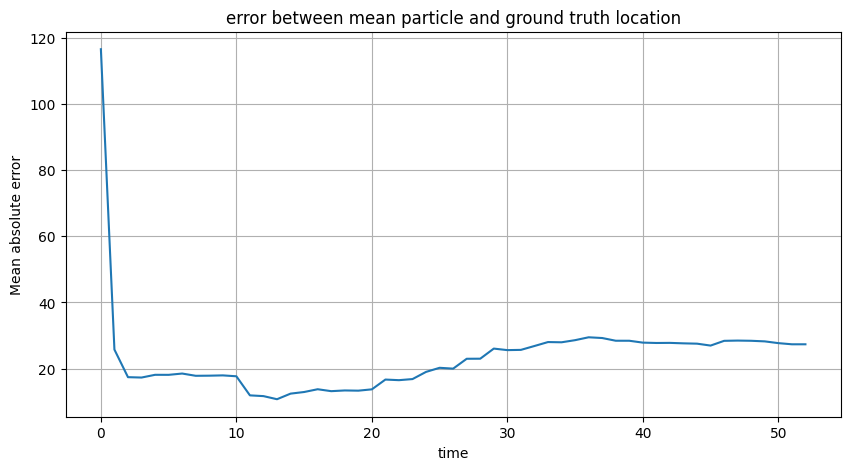

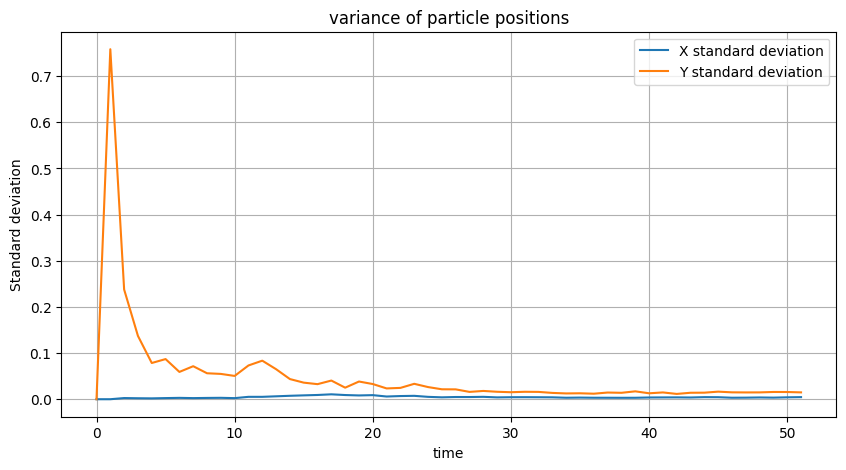

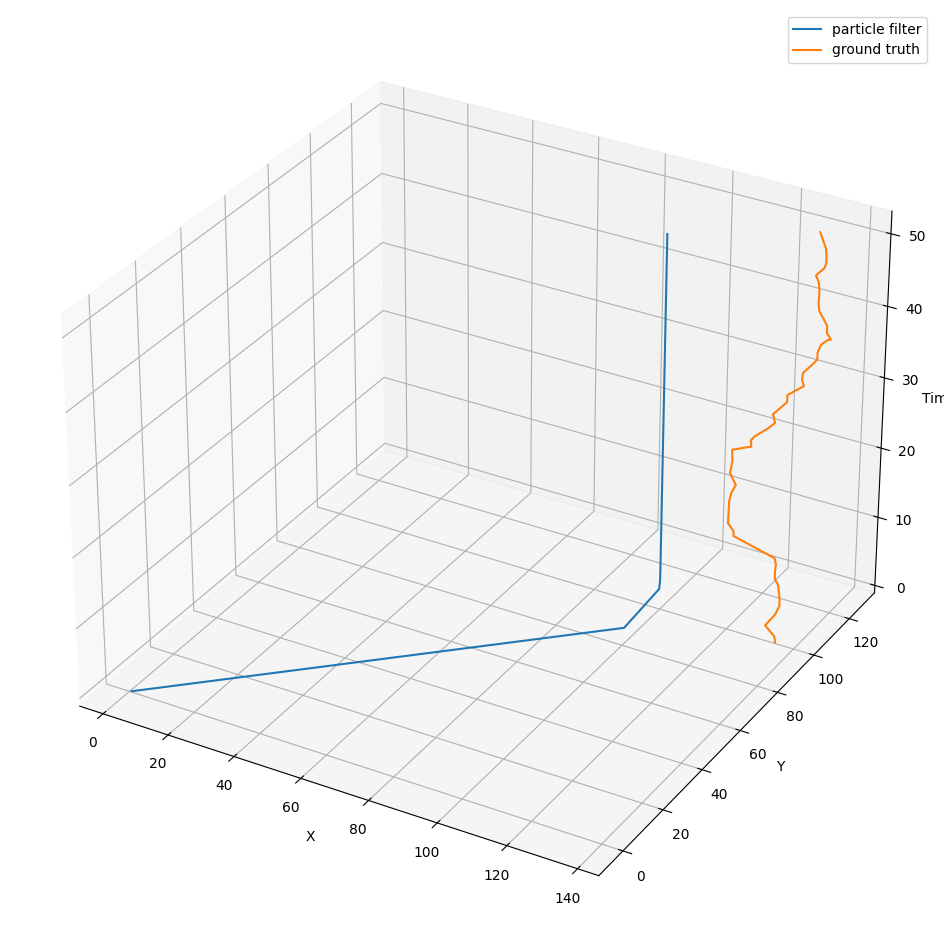

In [10]:
# for you to implement
# plot the error_log
# plot std_log
# plot the trajectory of the real path and your predicted path


plt.figure(figsize=(10, 5))

plt.plot(error_log)

plt.title("error between mean particle and ground truth location")
plt.xlabel("time")
plt.ylabel("Mean absolute error")
plt.grid(True)
plt.show()


###################################################################


std_log = np.array(std_log)

plt.figure(figsize=(10, 5))

plt.plot(std_log[:, 0], label="X standard deviation")
plt.plot(std_log[:, 1], label="Y standard deviation")

plt.title("variance of particle positions")
plt.xlabel("time")
plt.ylabel("Standard deviation")
plt.legend()
plt.grid(True)
plt.show()


###################################################################

fig = plt.figure(figsize=(12, 12))
ax = fig.add_subplot(projection="3d")

position_log = np.array(position_log)
ground_truth_array = np.array(ground_truth)

ax.plot(
    position_log[:, 0],
    position_log[:, 1],
    np.arange(len(position_log)),
    label="particle filter",
)

ax.plot(
    ground_truth_array[:, 0],
    ground_truth_array[:, 1],
    np.arange(len(ground_truth_array)),
    label="ground truth",
)

ax.set_xlabel("X")
ax.set_ylabel("Y")
ax.set_zlabel("Time")

plt.legend(["particle filter", "ground truth"])
plt.show()

Provide a short analysis of all resulted graphs.

**1. Estimation error over time**

The error graph shows how accurately the estimated position follows the ground truth. A decreasing error indicates that the filter is using the sensor observations to improve its estimate. Fluctuations can occur because of random movement and noisy measurements. If the error increases substantially, the movement model, particle distribution, or sensor observations may not be providing enough information for accurate tracking.

**2. Particle spread over time**

The standard-deviation graph indicates the uncertainty in the estimated position. A large spread means the particles occupy a wider range of coordinates, making the position less certain. A smaller spread indicates that the particles are more concentrated. However, a small spread does not necessarily mean the estimate is correct: resampling can concentrate particles around an incorrect location.

**3. Estimated trajectory and uncertainty**

The trajectory plot compares the estimated path with the ground-truth path. When the two paths are close together, the filter is tracking the individual accurately. When they diverge, the position estimate is less accurate. The error bars show the coordinate-wise spread of the particles and help identify time steps where the estimated position is uncertain.

**4. Three-dimensional trajectory**

The three-dimensional plot displays the evolution of both trajectories over time. The horizontal axes represent the spatial coordinates, while the vertical axis represents time. Similar paths indicate good tracking performance, whereas substantial separation indicates larger estimation errors. Changes in the separation over time can reveal periods when the observations provide stronger or weaker localization information.

Overall, the error and spread plots should be interpreted together. Low estimation error and relatively small particle spread generally indicate good performance, while high error and large spread indicate greater uncertainty.

## C. Analysis of different k values
Briefly explain what values of $k$ would eventually lead to better predictions?

The best value of \(k\) depends on the actual movement dynamics of the individual. In the implemented model, the expected travel distance is multiplied by \(k\) at each time step.

- When \(0 < k < 1\), the expected travel distance decreases over time. This is appropriate if the individual gradually slows down due to fatigue.
- When \(k = 1\), the expected travel distance remains constant. This is appropriate if the individual maintains a relatively constant expected pace.
- When \(k > 1\), the expected travel distance increases over time. This may be appropriate if the individual accelerates, but it can also increase uncertainty if the actual movement does not accelerate.

Therefore, no single value of \(k\) is always best. The most suitable value is the one that best matches the actual movement process. If the ground-truth trajectory is available for evaluation, different candidate values can be tested and compared using mean absolute error or root mean squared error. The value producing the lowest validation error can then be selected, while avoiding overfitting to a single trajectory.